# Projet Steam : analyse du marché du jeu vidéo

**Contexte.** Ubisoft prépare un nouveau jeu et veut comprendre le marché
Steam ainsi que les facteurs qui rendent un jeu populaire.

**Données.** `steam_game_output.json` (S3 Jedha), environ 55 000 jeux.

**Outils.** PySpark sur Databricks pour le traitement, Plotly et
statsmodels pour les graphiques et la régression.

**Etapes du projet**
1. ETL : extraire, nettoyer, charger, contrôler
2. Analyse macro
3. Analyse des genres
4. Analyse des plateformes
5. Facteurs de popularité (régression)
6. Conclusions

**Hypothèses**
- Les prix sont en dollars et stockés en centimes dans la source.
- `owners` est une tranche (ex. « 20 000 .. 50 000 ») : on prend le
  milieu. Le revenu estimé (`owners × prix`) est donc un ordre de
  grandeur, pas une mesure exacte.

In [0]:
%pip install -q plotly statsmodels

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import numpy as np
import pandas as pd
import plotly.express as px
import statsmodels.formula.api as smf
from pyspark.sql import Window
from pyspark.sql import functions as F
from scipy import stats

SOURCE = (
    "s3://full-stack-bigdata-datasets/Big_Data/Project_Steam/"
    "steam_game_output.json"
)

# Nous ne tiendrons compte au classement que des genres représentés par au moins 300 jeux.
MIN_GAMES = 300

# Les "genres" ci-dessous sont en fait des statuts ou des logiciels, et non des types de jeux à proprement parler.
NOT_GAME_GENRES = [
    "Early Access", "Free to Play", "Utilities", "Animation & Modeling",
    "Design & Illustration", "Education", "Video Production",
    "Audio Production", "Photo Editing", "Web Publishing",
    "Software Training", "Game Development", "Accounting",
]

## 1. ETL

### 1.1 Extraction

Lecture du fichier JSON. Spark identifie le schéma des données.

In [0]:
raw = spark.read.json(SOURCE)
print(f"Nombre de lignes : {raw.count()}")

Nombre de lignes : 55691


### 1.2 Transformation

Les données sont imbriquées dans la colonne `data`. Nous sélectionnons les
colonnes utiles, puis nous créons les colonnes dont nous aurons besoin ensuite pour l'analyse.

In [0]:
# Étape 1 : aplatir et renommer
flat = raw.select(
    F.col("data.appid").alias("id"),
    F.col("data.name").alias("title"),
    F.col("data.type").alias("type"),
    F.col("data.publisher").alias("publisher"),
    F.col("data.genre").alias("genre_raw"),
    F.col("data.initialprice").cast("double").alias("price_cents"),
    F.col("data.discount").cast("int").alias("discount"),
    F.col("data.release_date").alias("date_raw"),
    F.col("data.required_age").alias("age_raw"),
    F.col("data.languages").alias("languages_raw"),
    F.col("data.owners").alias("owners_raw"),
    F.col("data.positive").alias("positive"),
    F.col("data.negative").alias("negative"),
    F.col("data.platforms.windows").alias("is_windows"),
    F.col("data.platforms.mac").alias("is_mac"),
    F.col("data.platforms.linux").alias("is_linux"),
)

# Étape 2 : conserver les jeux uniquement, et éliminer les éventuels doublons 
games = flat.filter(F.col("type") == "game").dropDuplicates(["id"])

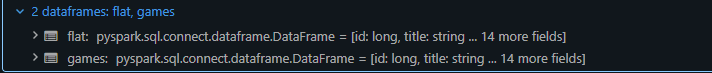

In [0]:
# Étape 3 : créer les colonnes d'analyse
owners_text = F.regexp_replace("owners_raw", ",", "")
owners_pattern = r"(\d+)\s*\.\.\s*(\d+)"
low = F.regexp_extract(owners_text, owners_pattern, 1)
high = F.regexp_extract(owners_text, owners_pattern, 2)

df = (
    games
    # Prix en dollars
    .withColumn("price", F.col("price_cents") / 100)
    .withColumn("is_free", F.col("price") == 0)
    .withColumn("has_discount", F.coalesce("discount", F.lit(0)) > 0)
    # Éditeur : regrouper toutes les entités Ubisoft (apparait plusieurs fois avec un nom différent)
    .withColumn(
        "publisher",
        F.when(
            F.lower("publisher").startswith("ubisoft"), F.lit("Ubisoft")
        ).otherwise(F.trim("publisher")),
    )
    .withColumn(
        "publisher",
        F.when(F.col("publisher") == "", None).otherwise(F.col("publisher")),
    )
    # Date de sortie (null si le format n'est pas reconnu)
    .withColumn("release_date", F.try_to_date("date_raw", F.lit("yyyy/M/d")))
    .withColumn("release_year", F.year("release_date"))
    # Âge requis : le premier nombre trouvé, sinon 0
    .withColumn(
        "required_age",
        F.when(
            F.col("age_raw").rlike(r"\d"),
            F.regexp_extract("age_raw", r"(\d+)", 1).cast("int"),
        ).otherwise(0),
    )
    # Nombre de langues
    .withColumn(
        "n_languages",
        F.when(F.col("languages_raw").isNull(), 0)
        .otherwise(F.size(F.split("languages_raw", ", "))),
    )
    # Avis : null s'il n'y a aucun avis (et non 0 %)
    .withColumn("total_reviews", F.col("positive") + F.col("negative"))
    .withColumn(
        "rating_pct",
        F.when(
            F.col("total_reviews") > 0,
            F.round(F.col("positive") / F.col("total_reviews") * 100, 2),
        ),
    )
    # Propriétaires estimés : milieu de la tranche
    .withColumn("owners_low", F.when(low != "", low.cast("long")))
    .withColumn("owners_high", F.when(high != "", high.cast("long")))
    .withColumn(
        "owners_mid", (F.col("owners_low") + F.col("owners_high")) / 2
    )
    .withColumn("est_revenue", F.col("owners_mid") * F.col("price"))
    # Nombre de plateformes
    .withColumn(
        "n_platforms",
        F.col("is_windows").cast("int")
        + F.col("is_mac").cast("int")
        + F.col("is_linux").cast("int"),
    )
    .drop("price_cents", "date_raw", "age_raw", "owners_raw")
)
n_games = df.count()
print(f"ETL terminé : {n_games} jeux prêts.")
display(df.limit(5))

ETL terminé : 55690 jeux prêts.


id,title,type,publisher,genre_raw,discount,languages_raw,positive,negative,is_windows,is_mac,is_linux,price,is_free,has_discount,release_date,release_year,required_age,n_languages,total_reviews,rating_pct,owners_low,owners_high,owners_mid,est_revenue,n_platforms
1000470,Drawngeon: Dungeons of Ink and Paper,game,DarkDes Labs,"Adventure, Indie, RPG",0,"English, Russian, French, German, Spanish - Spain",55,13,true,false,false,4.99,false,false,2019-05-24,2019,0,5,68,80.88,20000,50000,35000.0,174650.0,1
1000990,Gun Beat,game,Gun Beat,"Action, Casual, Indie",0,English,8,3,true,false,false,6.99,false,false,2019-01-14,2019,0,1,11,72.73,0,20000,10000.0,69900.0,1
1001040,Glorious Companions,game,Ancient Forge,"RPG, Strategy, Early Access",0,"English, Polish, Portuguese - Brazil",66,39,true,false,false,19.99,false,false,2019-06-04,2019,0,3,105,62.86,0,20000,10000.0,199899.99999999997,1
1001960,Zibbs - Alien Survival,game,Mykhail Konokh,"Action, Indie",0,"English, Russian, Ukrainian",12,9,true,false,false,7.99,false,false,2020-11-08,2020,0,3,21,57.14,0,20000,10000.0,79900.0,1
1002360,バグダス - デバッガー検定 -,game,Jiruo Software,"Casual, Indie",0,Japanese,60,12,true,false,false,0.99,false,false,2019-01-21,2019,0,1,72,83.33,0,20000,10000.0,9900.0,1


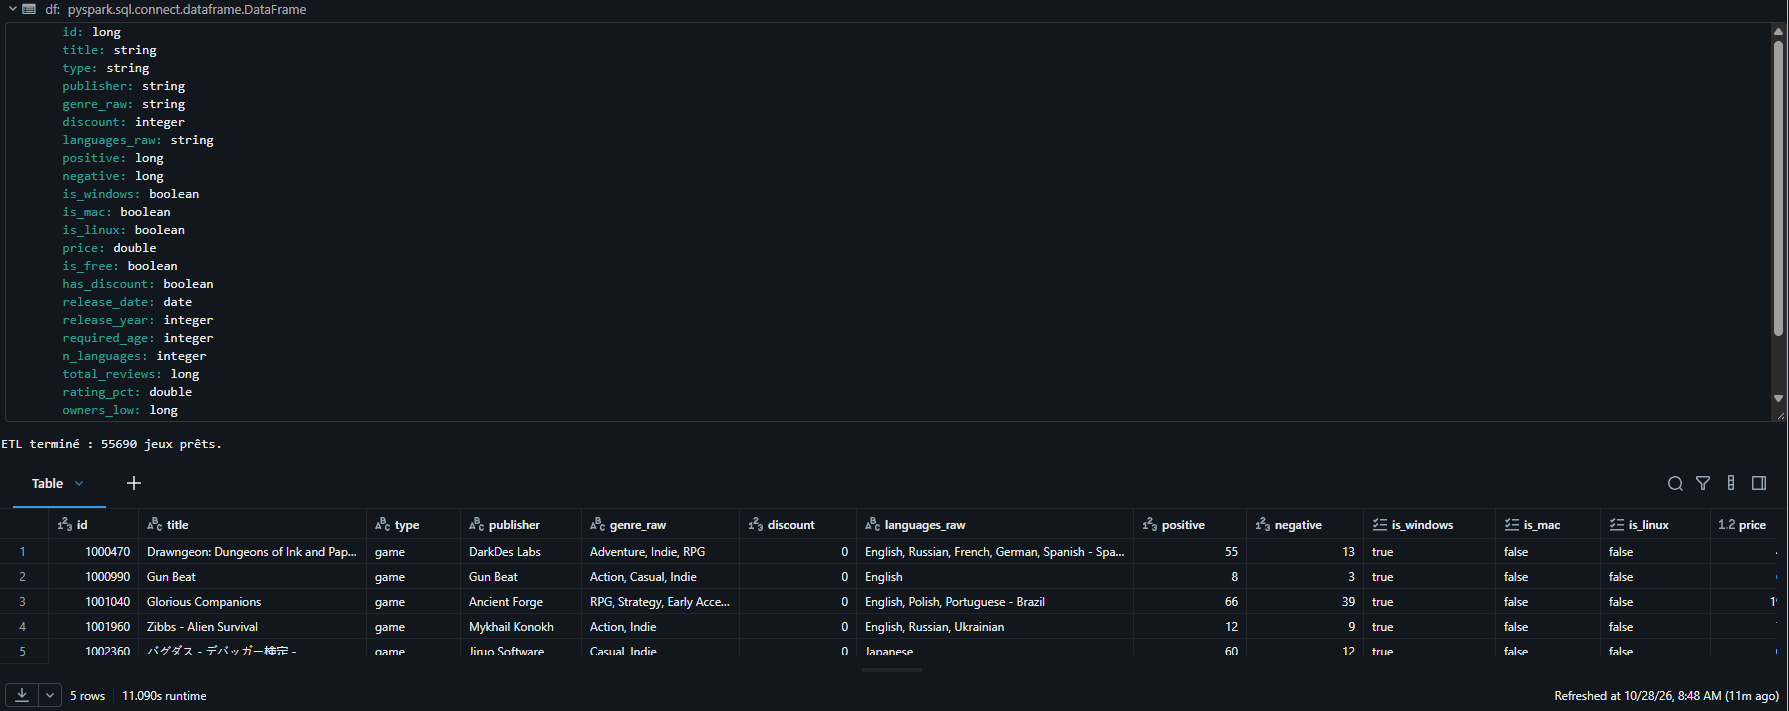

### 1.3 Chargement

Le résultat est enregistré dans une table Delta. Si Databricks refuse
l'écriture (droits), passer cette cellule : la suite du
notebook utilise le DataFrame `df`.

In [0]:
(
    df.write.mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("steam_games_clean")
)

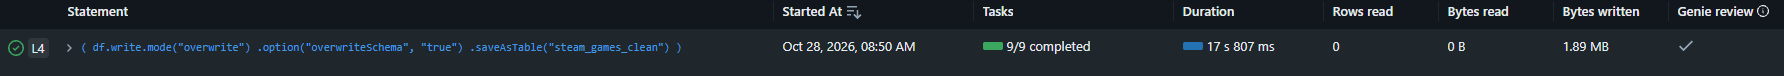

### 1.4 Contrôle qualité

On vérifie les doublons, les valeurs manquantes et les valeurs extrêmes.

In [0]:
print(f"Lignes lues         : {flat.count()}")
print(f"Jeux après filtres  : {n_games}")

# Pourcentage de valeurs manquantes par colonne
null_rates = df.select([
    F.round(F.avg(F.col(c).isNull().cast("int")) * 100, 2).alias(c)
    for c in df.columns
]).toPandas().T.reset_index()
null_rates.columns = ["colonne", "pct_null"]
display(null_rates.sort_values("pct_null", ascending=False))

Lignes lues         : 55691
Jeux après filtres  : 55690


colonne,pct_null
release_year,0.4
release_date,0.4
rating_pct,0.29
publisher,0.24
id,0.0
has_discount,0.0
est_revenue,0.0
owners_mid,0.0
owners_high,0.0
owners_low,0.0


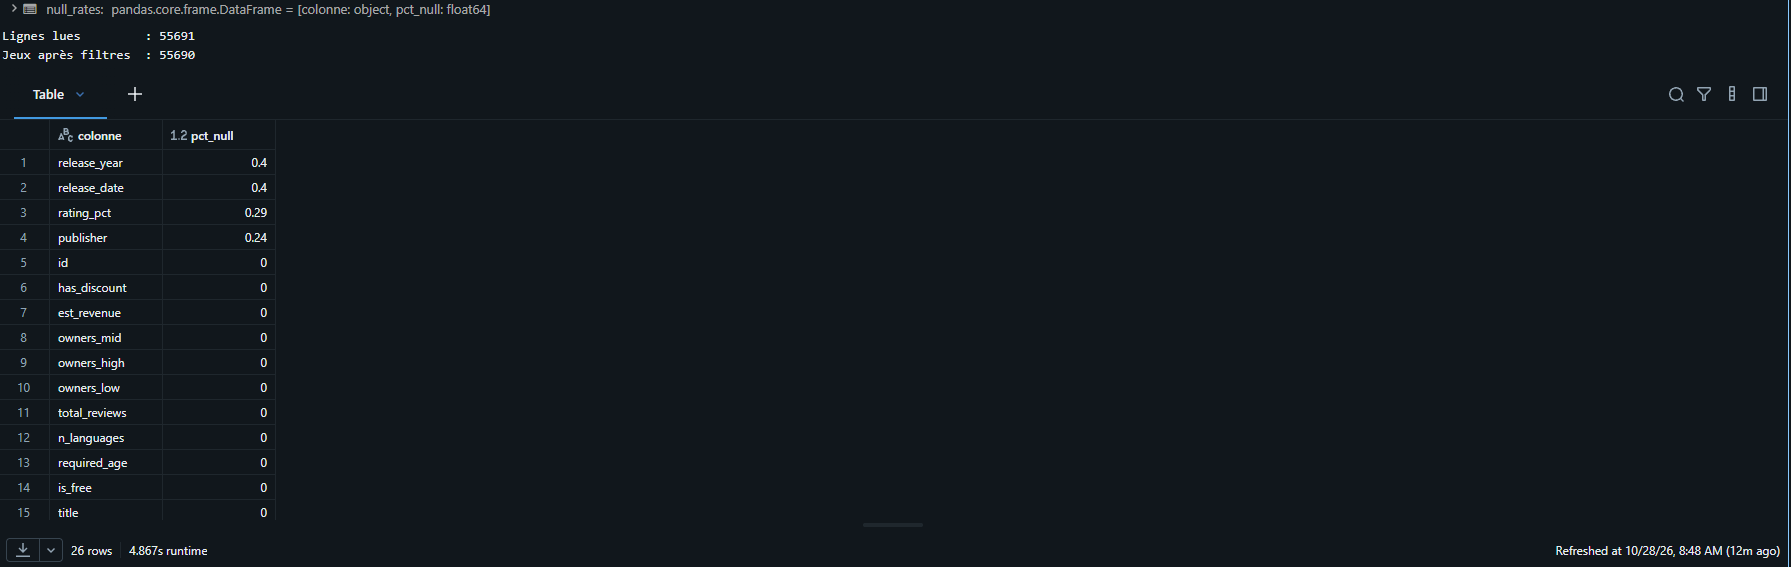

In [0]:
display(
    df.agg(
        F.min("release_date").alias("date_min"),
        F.max("release_date").alias("date_max"),
        F.min("price").alias("prix_min"),
        F.max("price").alias("prix_max"),
    )
)

date_min,date_max,prix_min,prix_max
1997-06-30,2022-11-11,0.0,999.0


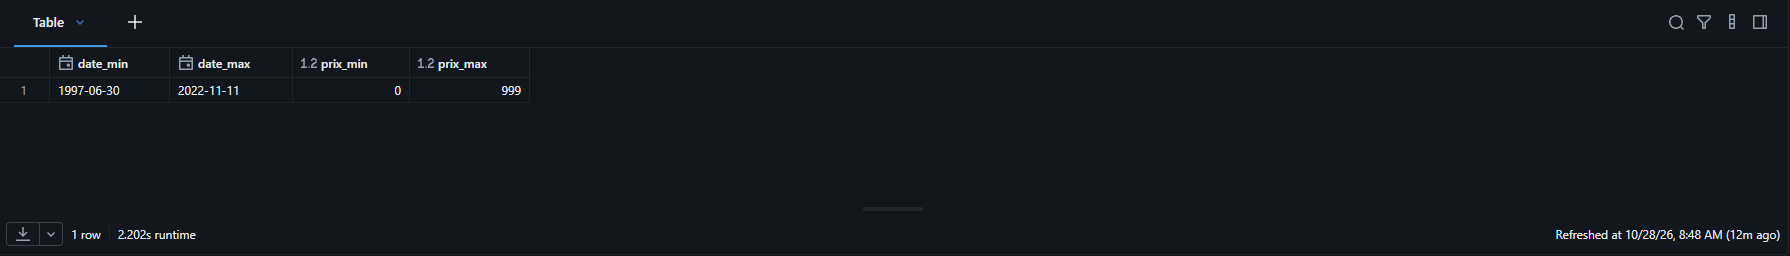

## 2. Analyse macro

### 2.1 Éditeurs qui ont sorti le plus de jeux

Les valeurs vides sont exclues. Un éditeur déclaré avec un co-éditeur
(« A, B ») est compté comme une entité à part.

In [0]:
publisher_counts = (
    df.filter(F.col("publisher").isNotNull())
    .groupBy("publisher")
    .agg(F.count("*").alias("nb_games"))
)
display(publisher_counts.orderBy(F.desc("nb_games")).limit(10))

publisher,nb_games
Big Fish Games,423
8floor,202
SEGA,165
Strategy First,151
Square Enix,141
Choice of Games,140
Ubisoft,135
HH-Games,132
Sekai Project,132
Laush Studio,126


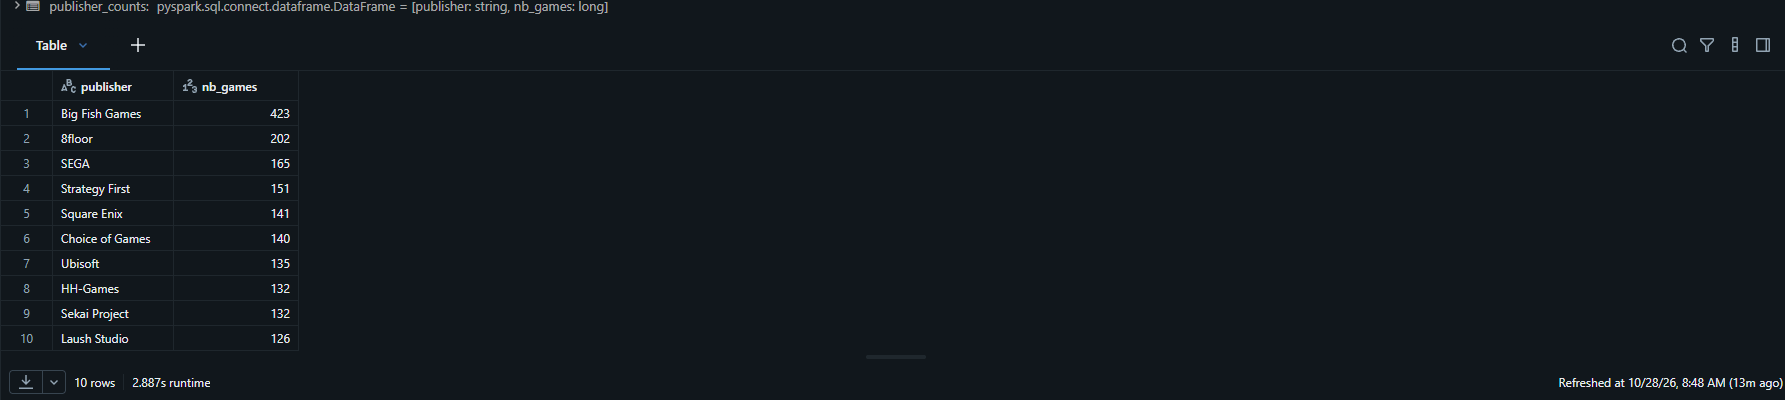

In [0]:
# Position d'Ubisoft
ubisoft_games = (
    publisher_counts.filter(F.col("publisher") == "Ubisoft")
    .first()["nb_games"]
)
ubisoft_rank = (
    publisher_counts.filter(F.col("nb_games") > ubisoft_games).count() + 1
)
print(f"Ubisoft : {ubisoft_games} jeux, rang {ubisoft_rank}")

Ubisoft : 135 jeux, rang 7


### 2.2 Jeux les mieux notés

Un jeu peut avoir 100% avec uniquement 3 avis. On ne garde que les jeux avec au moins 500 avis.

In [0]:
best_rated = (
    df.filter(F.col("total_reviews") >= 500)
    .select("title", "rating_pct", "total_reviews")
    .orderBy(F.desc("rating_pct"))
    .limit(10)
)
display(best_rated)

title,rating_pct,total_reviews
Flowers -Le volume sur ete-,99.89,938
Touhou Fuujinroku ~ Mountain of Faith.,99.39,653
Aventura Copilului Albastru și Urât,99.37,2217
The Case of the Golden Idol,99.34,915
Aseprite,99.33,11903
Patrick's Parabox,99.27,1500
A Short Hike,99.26,11732
Monster Prom 3: Monster Roadtrip,99.25,1060
Flowers -Le volume sur automne-,99.23,520
CULTIC,99.21,2037


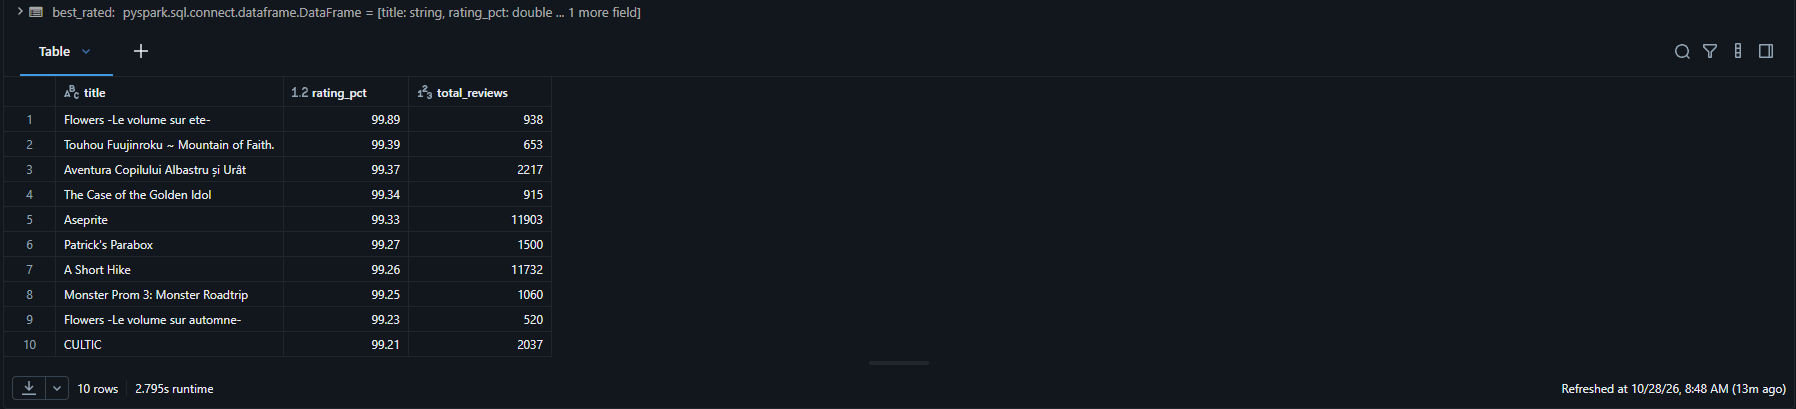

### 2.3 Sorties par année et période Covid

Les données s'arrêtent à `date_max` (voir contrôle qualité) : la dernière
année est incomplète.

In [0]:
yearly = (
    df.filter(F.col("release_year").isNotNull())
    .filter(F.col("release_year")>2011)
    .groupBy("release_year")
    .agg(F.count("*").alias("nb_games"))
    .orderBy("release_year")
    .toPandas()
)
# Évolution en % par rapport à l'année précédente
yearly["growth_pct"] = (yearly["nb_games"].pct_change() * 100).round(1)
display(yearly)

release_year,nb_games,growth_pct
2012,344,null
2013,469,36.3
2014,1550,230.5
2015,2565,65.5
2016,4176,62.8
2017,6006,43.8
2018,7663,27.6
2019,6949,-9.3
2020,8287,19.3
2021,8805,6.3


Databricks visualization. Run in Databricks to view.

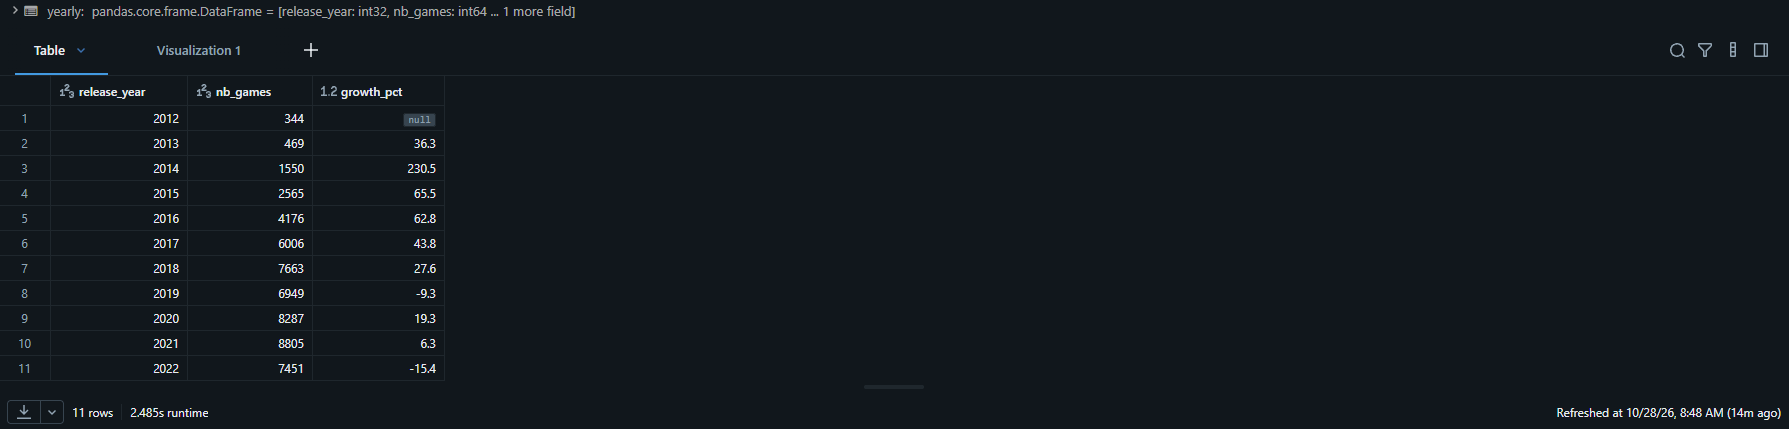

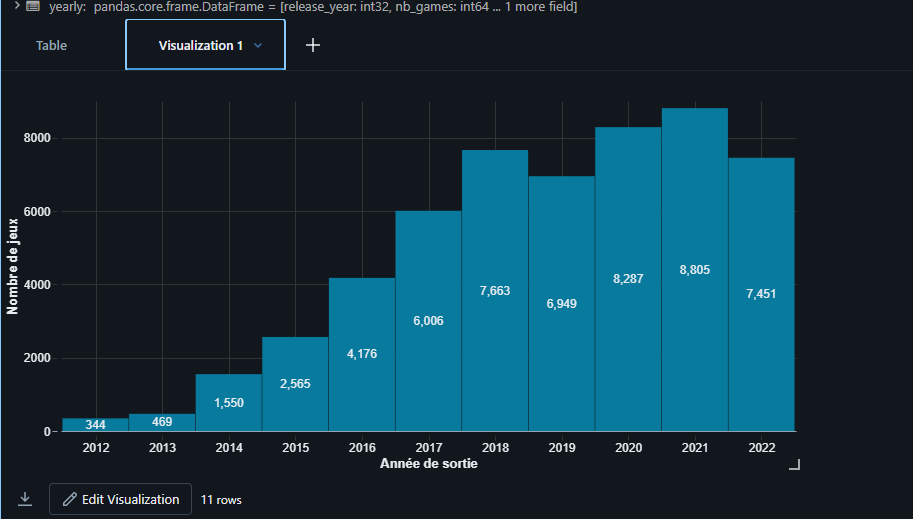

In [0]:
fig = px.bar(
    yearly[yearly["release_year"] >= 2005],
    x="release_year",
    y="nb_games",
    title="Nombre de jeux sortis sur Steam par année",
    labels={"release_year": "Année", "nb_games": "Nombre de jeux"},
)
fig.show()

<!doctype html>

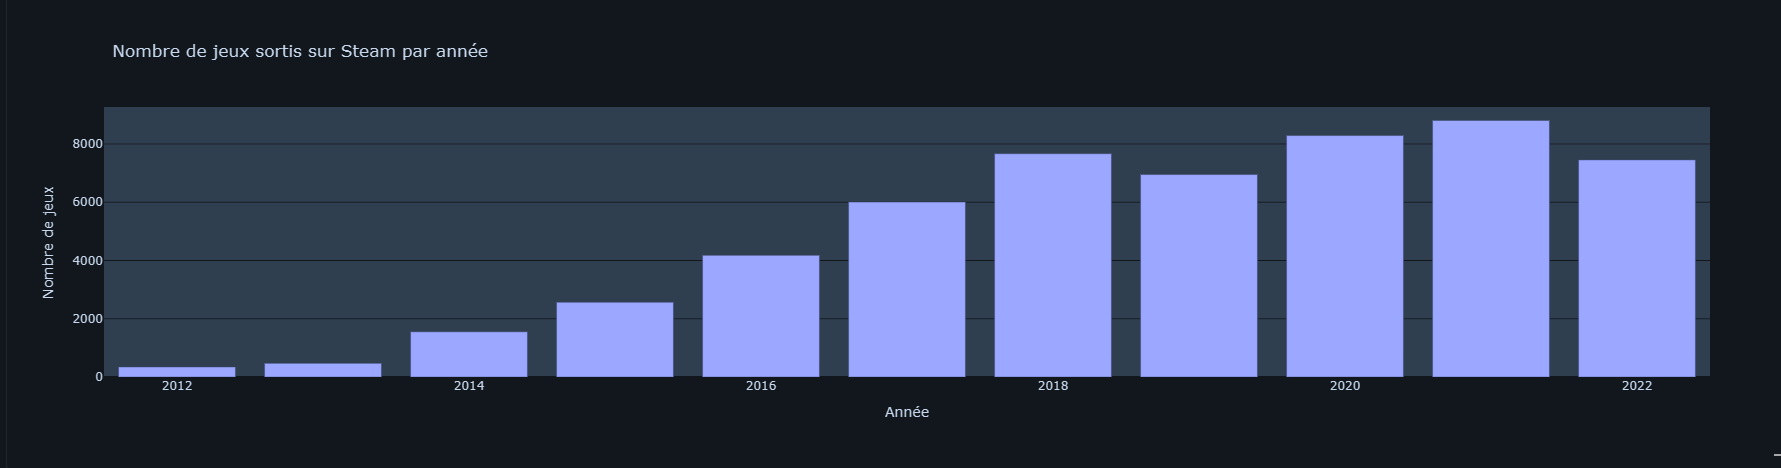

### 2.4 Prix et promotions

In [0]:
display(
    df.agg(
        F.round(F.avg(F.col("is_free").cast("int")) * 100, 1)
        .alias("pct_gratuits"),
        F.round(F.avg(F.col("has_discount").cast("int")) * 100, 1)
        .alias("pct_en_promotion"),
    )
)

# Prix des jeux payants
paid = df.filter(F.col("price") > 0)
display(
    paid.agg(
        F.round(F.avg("price"), 2).alias("moyenne"),
        F.percentile_approx("price", 0.5).alias("mediane"),
        F.percentile_approx("price", 0.9).alias("p90"),
        F.max("price").alias("max"),
    )
)

pct_gratuits,pct_en_promotion
14.0,4.5


moyenne,mediane,p90,max
9.27,5.99,19.99,999.0


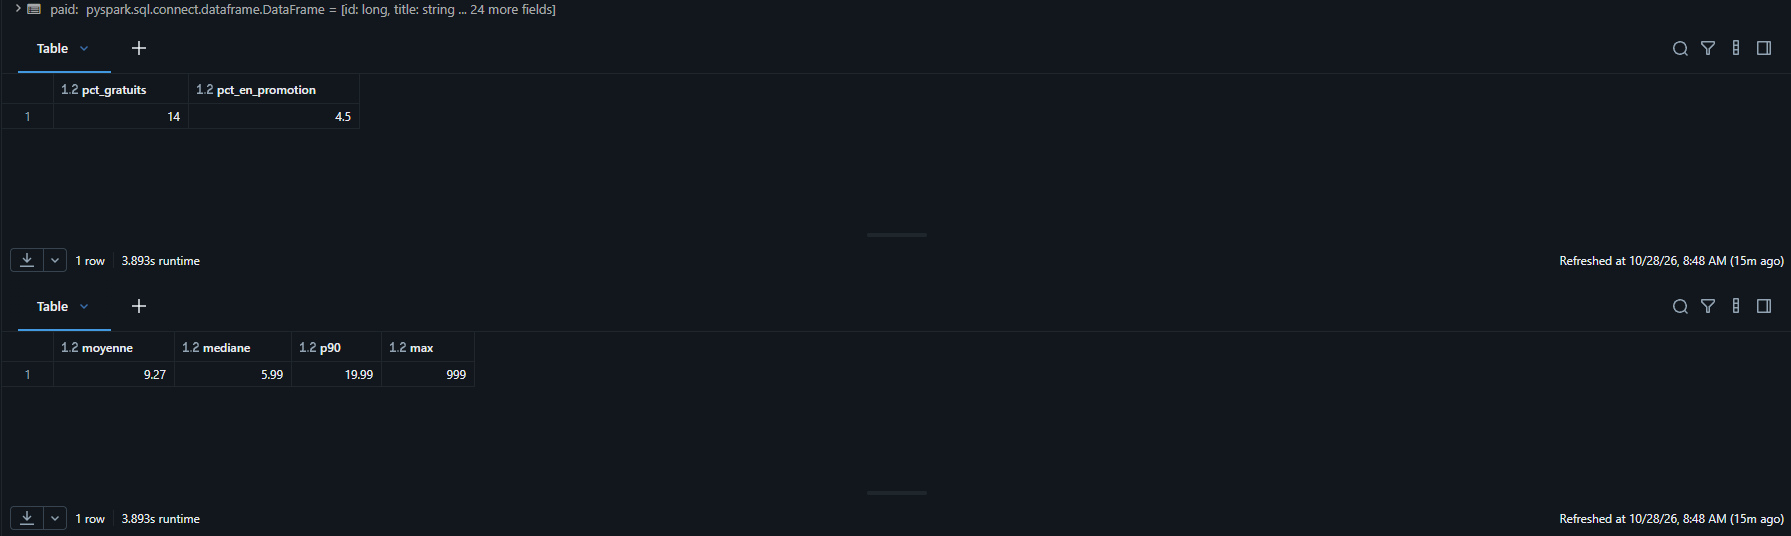

In [0]:
# Répartition par tranche de prix
price_bucket = (
    F.when(F.col("price") == 0, "0 - Gratuit")
    .when(F.col("price") < 5, "1 - Moins de 5 $")
    .when(F.col("price") < 10, "2 - De 5 à 10 $")
    .when(F.col("price") < 20, "3 - De 10 à 20 $")
    .when(F.col("price") < 40, "4 - De 20 à 40 $")
    .otherwise("5 - 40 $ et plus")
)
price_dist = (
    df.filter(F.col("price").isNotNull())
    .groupBy(price_bucket.alias("tranche_prix"))
    .agg(F.count("*").alias("nb_games"))
    .withColumn("pct", F.round(F.col("nb_games") / n_games * 100, 1))
    .orderBy("tranche_prix")
)
display(price_dist)

tranche_prix,nb_games,pct
0 - Gratuit,7779,14.0
1 - Moins de 5 $,22742,40.8
2 - De 5 à 10 $,12688,22.8
3 - De 10 à 20 $,9375,16.8
4 - De 20 à 40 $,2512,4.5
5 - 40 $ et plus,594,1.1


Databricks visualization. Run in Databricks to view.

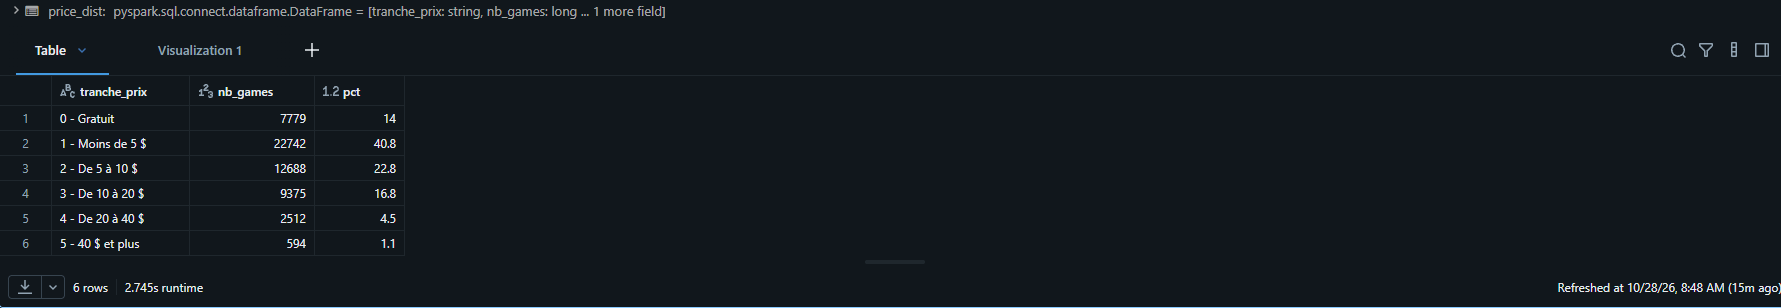

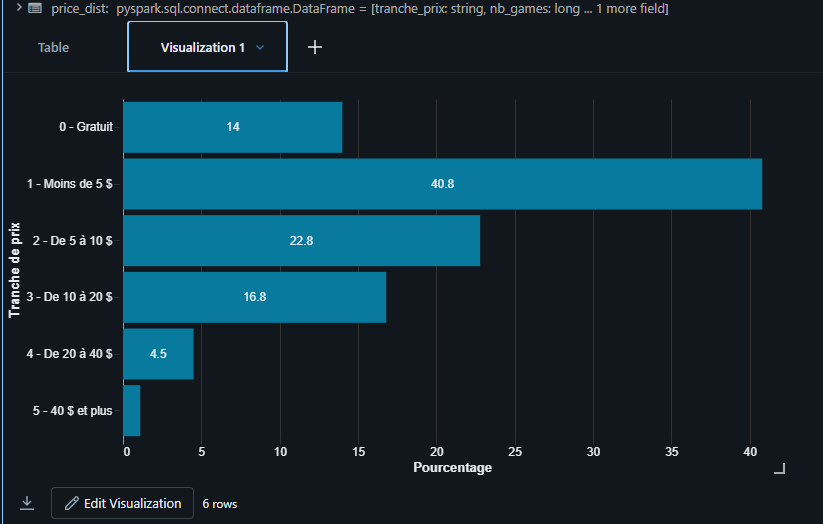

### 2.5 Langues les plus représentées

Un jeu compte une fois par langue. La part est calculée sur le nombre
de jeux.

In [0]:
languages = (
    df.select(F.explode(F.split("languages_raw", ", ")).alias("language"))
    .filter(F.col("language") != "Not supported")
    .groupBy("language")
    .agg(F.count("*").alias("nb_games"))
    .withColumn("pct_games", F.round(F.col("nb_games") / n_games * 100, 1))
    .orderBy(F.desc("nb_games"))
    .limit(10)
)
display(languages)

# Nombre moyen de langues par jeu
display(df.agg(F.round(F.avg("n_languages"), 2).alias("langues_moyenne")))

language,nb_games,pct_games
English,55116,99.0
German,14019,25.2
French,13426,24.1
Russian,12922,23.2
Simplified Chinese,12782,23.0
Spanish - Spain,12233,22.0
Japanese,10368,18.6
Italian,9304,16.7
Portuguese - Brazil,6750,12.1
Korean,6599,11.8


langues_moyenne
3.63


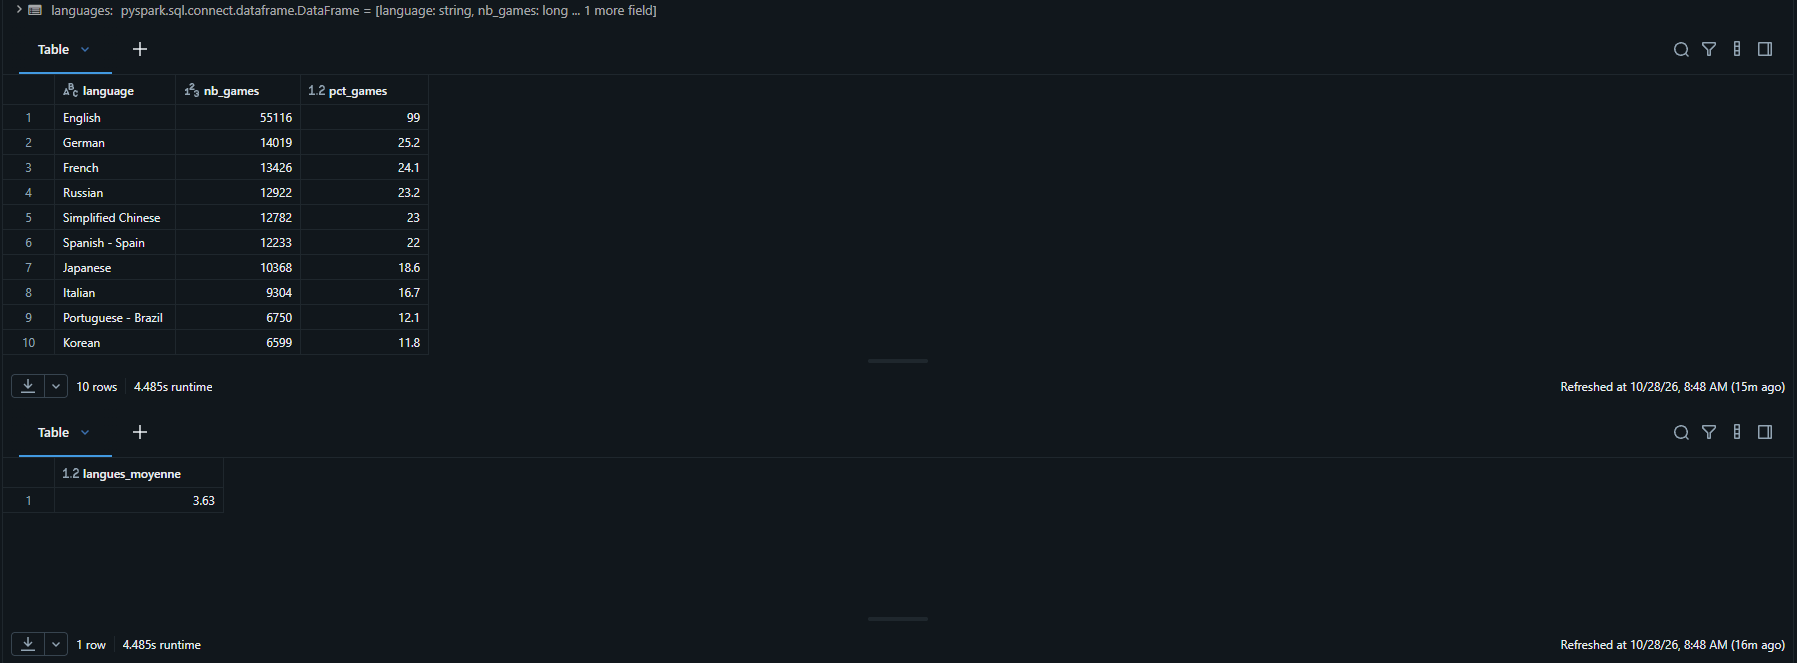

### 2.6 Jeux déconseillés aux mineurs

In [0]:
age_group = (
    F.when(F.col("required_age") >= 18, "4 - 18 ans et plus")
    .when(F.col("required_age") >= 16, "3 - 16-17 ans")
    .when(F.col("required_age") > 0, "2 - Moins de 16 ans")
    .otherwise("1 - Tous publics")
)
age_dist = (
    df.groupBy(age_group.alias("age_requis"))
    .agg(F.count("*").alias("nb_games"))
    .withColumn("pct", F.round(F.col("nb_games") / n_games * 100, 1))
    .orderBy("age_requis")
)
display(age_dist)

age_requis,nb_games,pct
1 - Tous publics,55029,98.8
2 - Moins de 16 ans,355,0.6
3 - 16-17 ans,76,0.1
4 - 18 ans et plus,230,0.4


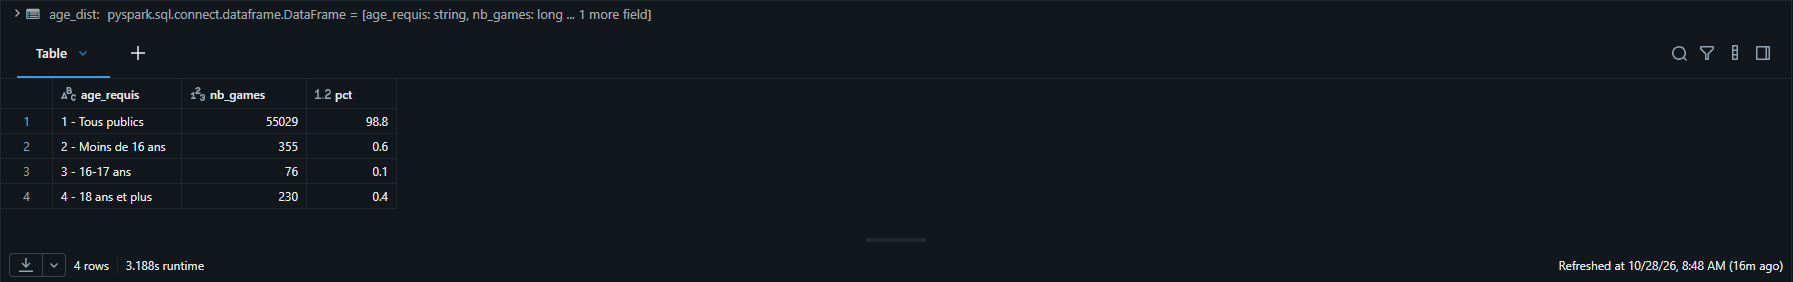

## 3. Analyse des genres

Un jeu peut avoir plusieurs genres. On crée donc une ligne par couple
(jeu, genre) avec `explode`. Les statuts et les genres « logiciels »
(voir `NOT_GAME_GENRES`) sont écartés.

In [0]:
df_genres = (
    df.select(
        "id", "publisher", "price", "positive", "negative",
        "total_reviews", "est_revenue", "is_linux", "is_mac",
        F.explode(F.split("genre_raw", ", ")).alias("genre"),
    )
    .filter(~F.col("genre").isin(NOT_GAME_GENRES))
)

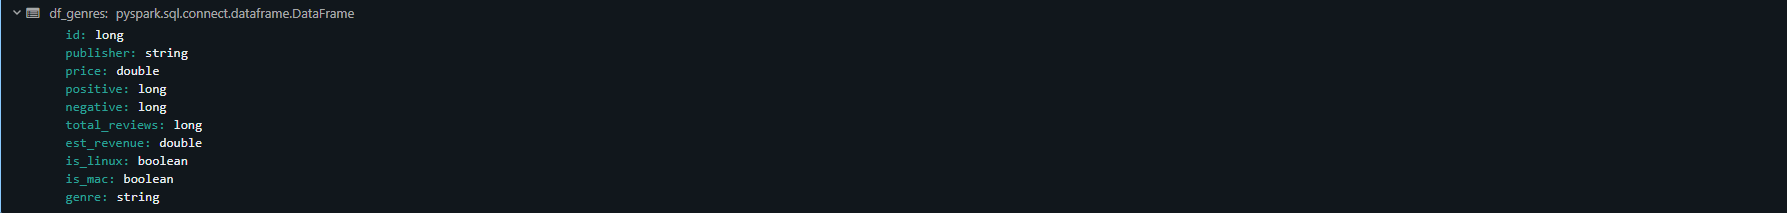

### 3.1 Genres les plus représentés

In [0]:
genre_counts = (
    df_genres.groupBy("genre")
    .agg(F.count("*").alias("nb_games"))
    .withColumn("pct_games", F.round(F.col("nb_games") / n_games * 100, 1))
    .orderBy(F.desc("nb_games"))
)
display(genre_counts.limit(10))

genre,nb_games,pct_games
Indie,39681,71.3
Action,23759,42.7
Casual,22086,39.7
Adventure,21431,38.5
Strategy,10895,19.6
Simulation,10836,19.5
RPG,9534,17.1
Sports,2666,4.8
Racing,2155,3.9
Massively Multiplayer,1460,2.6


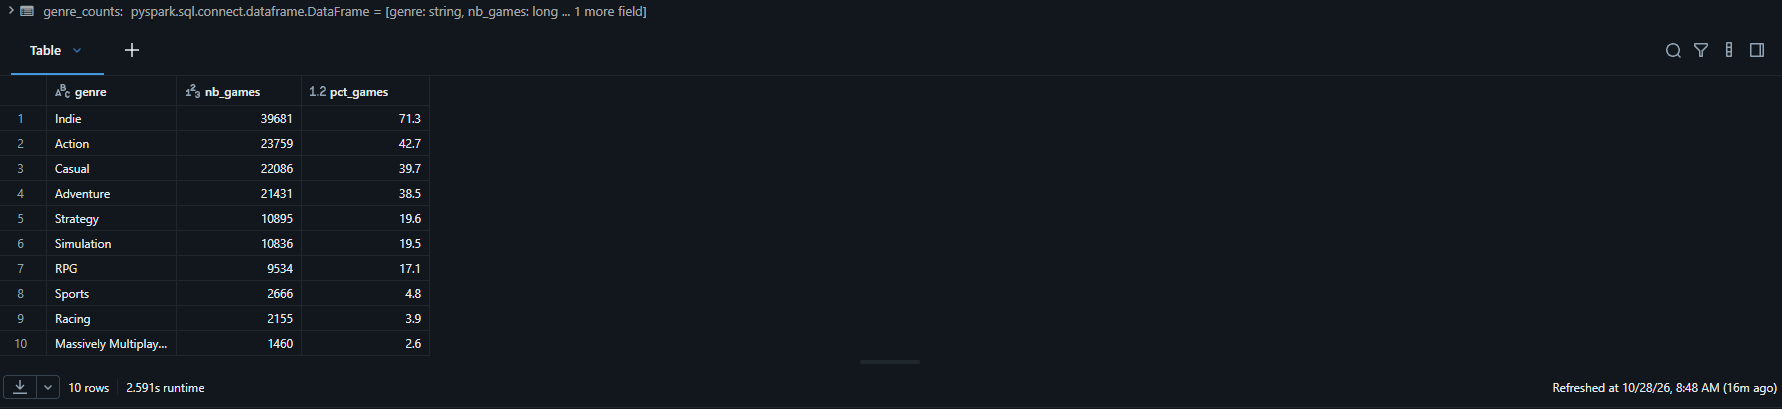

### 3.2 Genres avec le meilleur ratio d'avis positifs

On additionne tous les avis positifs du genre et on divise par tous les
avis du genre. Ainsi, un jeu avec 200 000 avis pèse plus qu'un jeu avec
1 avis. On ne garde que les genres d'au moins `MIN_GAMES` jeux.

In [0]:
genre_rating = (
    df_genres.groupBy("genre")
    .agg(
        F.count("*").alias("nb_games"),
        F.round(
            F.sum("positive") / F.sum("total_reviews") * 100, 2
        ).alias("weighted_rating_pct"),
    )
    .filter(F.col("nb_games") >= MIN_GAMES)
    .orderBy(F.desc("weighted_rating_pct"))
)
display(genre_rating)

genre,nb_games,weighted_rating_pct
Indie,39681,88.47
Casual,22086,86.72
Simulation,10836,86.64
Racing,2155,85.91
RPG,9534,85.58
Action,23759,84.99
Strategy,10895,84.85
Adventure,21431,84.0
Sports,2666,80.32
Massively Multiplayer,1460,73.08


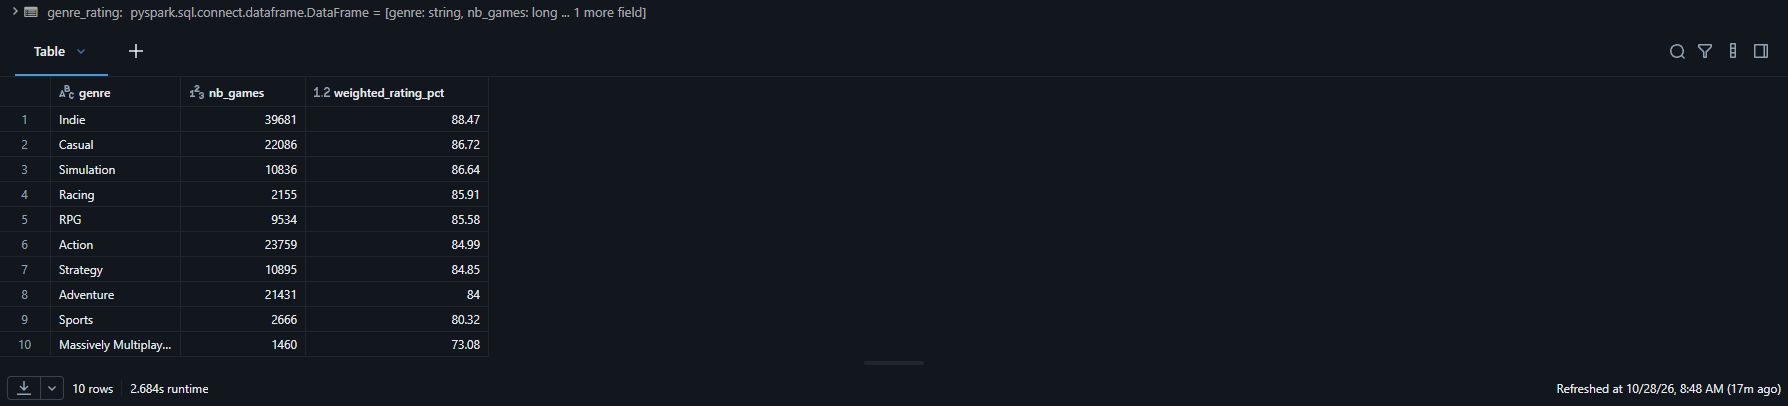

### 3.3 Genres favoris des principaux éditeurs

Pour les 10 éditeurs les plus prolifiques et Ubisoft : leurs 3 genres les
plus fréquents.

In [0]:
top_publishers = [
    row["publisher"]
    for row in publisher_counts.orderBy(F.desc("nb_games")).limit(10).collect()
]
top_publishers.append("Ubisoft")

publisher_genre = (
    df_genres.filter(F.col("publisher").isin(top_publishers))
    .groupBy("publisher", "genre")
    .agg(F.count("*").alias("nb_games"))
)
# On classe les genres de chaque éditeur du plus au moins fréquent
by_publisher = Window.partitionBy("publisher").orderBy(F.desc("nb_games"))
favorite_genres = (
    publisher_genre
    .withColumn("rang", F.row_number().over(by_publisher))
    .filter(F.col("rang") <= 3)
    .orderBy("publisher", "rang")
)
display(favorite_genres)

publisher,genre,nb_games,rang
8floor,Casual,202,1
8floor,Strategy,22,2
8floor,Simulation,10,3
Big Fish Games,Casual,419,1
Big Fish Games,Adventure,393,2
Big Fish Games,Simulation,7,3
Choice of Games,RPG,139,1
Choice of Games,Indie,136,2
Choice of Games,Adventure,112,3
HH-Games,Casual,132,1


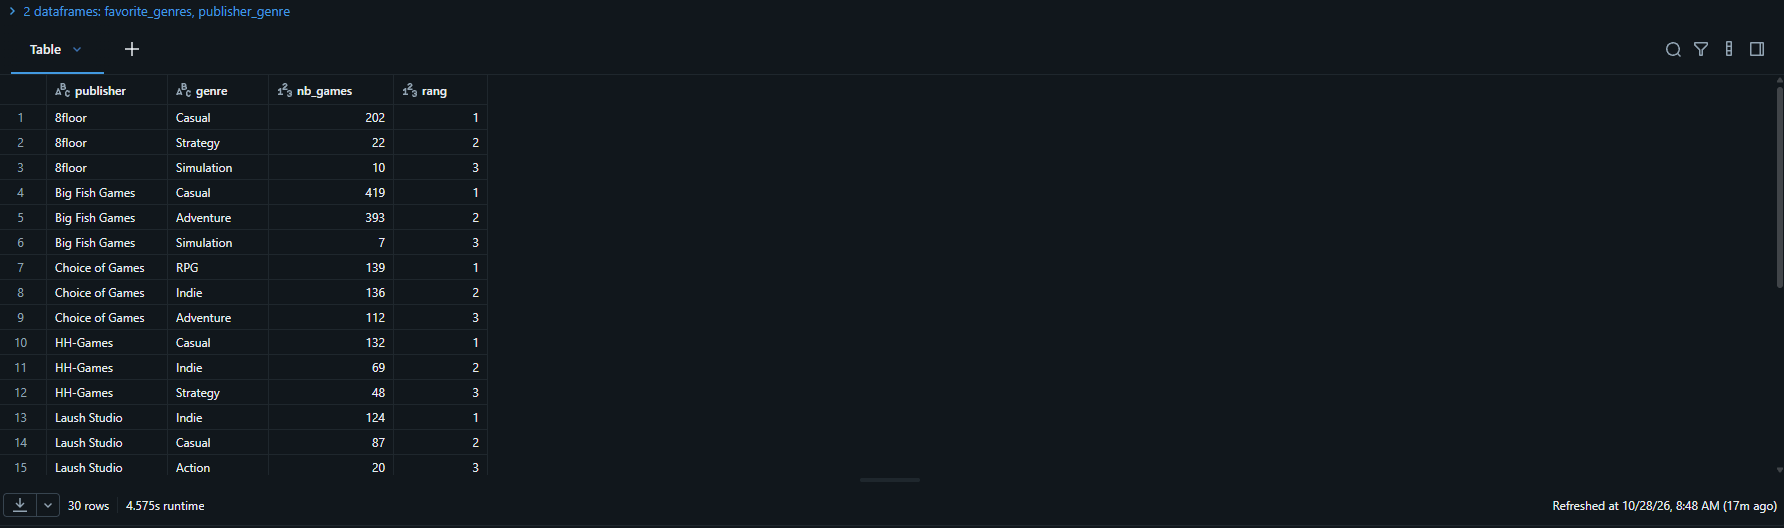

### 3.4 Genres les plus lucratifs

Le prix moyen ne mesure pas la rentabilité. On estime un revenu par jeu :
`propriétaires estimés × prix`. On regarde la **médiane** par jeu (plus
fiable que le total, qui dépend des quelques très gros succès). Ordre de
grandeur uniquement.

In [0]:
genre_revenue = (
    df_genres.filter(F.col("est_revenue").isNotNull())
    .groupBy("genre")
    .agg(
        F.count("*").alias("nb_games"),
        F.round(F.percentile_approx("est_revenue", 0.5), 0)
        .alias("revenu_median_usd"),
        F.round(F.avg("price"), 2).alias("prix_moyen_usd"),
    )
    .filter(F.col("nb_games") >= MIN_GAMES)
    .orderBy(F.desc("revenu_median_usd"))
)
display(genre_revenue)

genre,nb_games,revenu_median_usd,prix_moyen_usd
RPG,9534,99900.0,9.36
Simulation,10836,89900.0,9.38
Strategy,10895,89900.0,8.66
Adventure,21431,79900.0,8.31
Sports,2666,69900.0,9.26
Action,23759,69900.0,7.98
Indie,39681,59900.0,6.8
Racing,2155,59900.0,8.47
Casual,22086,49900.0,5.8
Massively Multiplayer,1460,0.0,5.2


Databricks visualization. Run in Databricks to view.

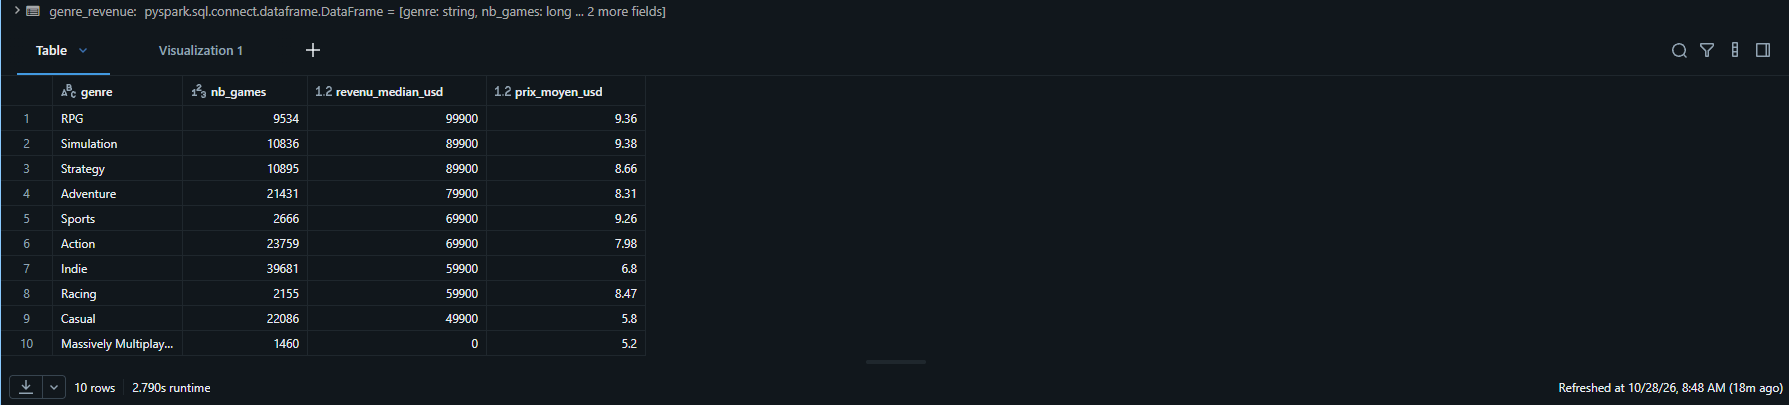

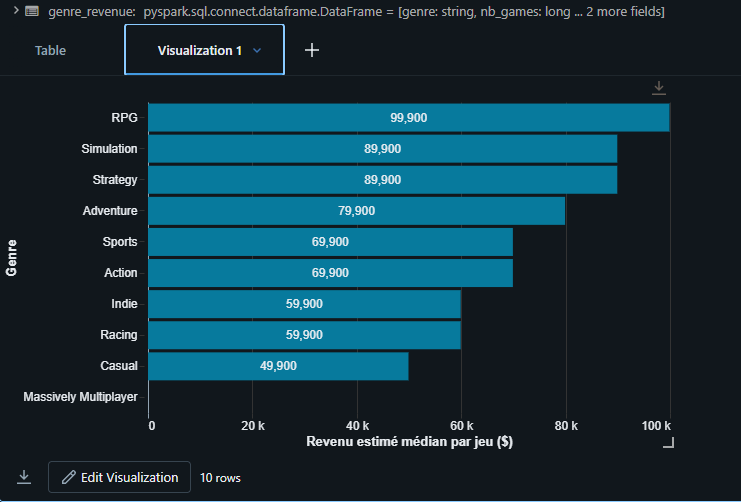

## 4. Analyse des plateformes

### 4.1 Disponibilité globale

In [0]:
platforms = df.agg(
    F.round(F.avg(F.col("is_windows").cast("int")) * 100, 1).alias("Windows"),
    F.round(F.avg(F.col("is_mac").cast("int")) * 100, 1).alias("Mac"),
    F.round(F.avg(F.col("is_linux").cast("int")) * 100, 1).alias("Linux"),
)
display(platforms)

# Part des jeux disponibles sur Windows uniquement
display(
    df.agg(
        F.round(
            F.avg(
                (F.col("is_windows") & ~F.col("is_mac") & ~F.col("is_linux"))
                .cast("int")
            ) * 100, 1
        ).alias("pct_windows_seul")
    )
)

Windows,Mac,Linux
100.0,22.9,15.2


pct_windows_seul
74.1


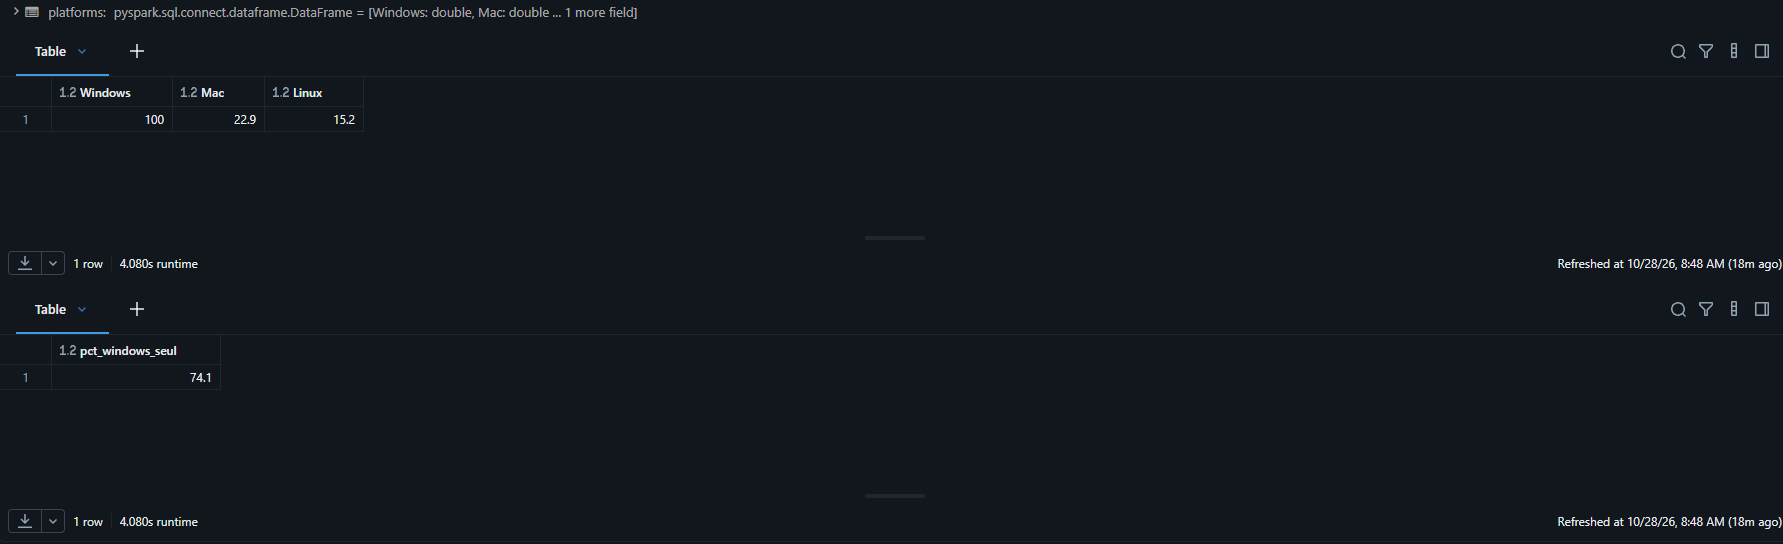

### 4.2 Genres et plateformes

Certains genres sont-ils davantage disponibles sur Mac ou Linux ? On ne
garde que les genres de plus de 500 jeux.

In [0]:
genre_platform = (
    df_genres.groupBy("genre")
    .agg(
        F.count("*").alias("nb_games"),
        F.round(F.avg(F.col("is_linux").cast("int")) * 100, 2)
        .alias("linux_pct"),
        F.round(F.avg(F.col("is_mac").cast("int")) * 100, 2)
        .alias("mac_pct"),
    )
    .filter(F.col("nb_games") > 500)
    .orderBy(F.desc("linux_pct"))
)
display(genre_platform)

genre,nb_games,linux_pct,mac_pct
Indie,39681,17.59,25.04
Strategy,10895,16.76,27.58
RPG,9534,15.98,23.58
Adventure,21431,15.41,23.51
Casual,22086,14.96,23.23
Action,23759,14.22,19.21
Simulation,10836,14.14,22.51
Racing,2155,14.11,19.68
Massively Multiplayer,1460,11.23,18.49
Sports,2666,10.77,18.98


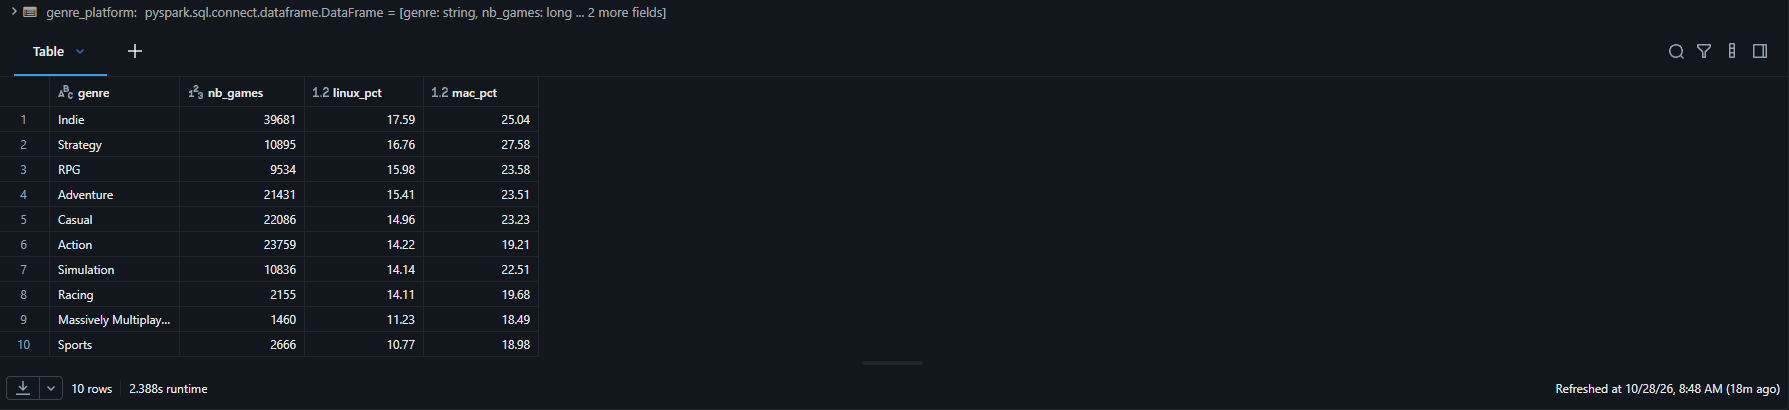

## 5. Facteurs de popularité

Objectif du projet : qu'est-ce qui est associé à la popularité d'un jeu ?
La popularité est mesurée par le nombre de propriétaires estimé, passé
en logarithme car très inégalement réparti.

### 5.1 Préparation

In [0]:
genre_list = [
    "Indie", "Action", "Casual", "Adventure", "Strategy", "Simulation", "RPG"
]
# Une colonne 0/1 par genre : « g_rpg » vaut 1 si le jeu est un RPG
dummies = [
    F.coalesce(F.col("genre_raw").contains(genre), F.lit(False))
    .cast("int")
    .alias("g_" + genre.lower())
    for genre in genre_list
]

features = (
    df.filter(
        (F.col("owners_mid") > 0)
        & F.col("price").isNotNull()
        & F.col("release_year").isNotNull()
    )
    .select(
        "owners_mid", "price", "n_languages", "n_platforms",
        "release_year", "rating_pct", "total_reviews",
        F.col("is_free").cast("int").alias("is_free"),
        F.col("is_mac").cast("int").alias("is_mac"),
        F.col("is_linux").cast("int").alias("is_linux"),
        (F.col("required_age") >= 16).cast("int").alias("age_16_plus"),
        *dummies,
    )
)
pdf = features.toPandas()

# Passage en échelle logarithmique
pdf["log_owners"] = np.log10(pdf["owners_mid"])
pdf["log_price"] = np.log10(1 + pdf["price"])
pdf["log_reviews"] = np.log10(1 + pdf["total_reviews"])
pdf["year_c"] = pdf["release_year"] - 2015
print(f"{len(pdf)} jeux retenus")
display(pdf.describe().T.reset_index())

55468 jeux retenus


index,count,mean,std,min,25%,50%,75%,max
owners_mid,55468.0,131692.05668132976,1845431.6624930135,10000.0,10000.0,10000.0,35000.0,3.5E8
price,55468.0,7.980056969784379,11.0463798749752,0.0,1.99,4.99,9.99,999.0
n_languages,55468.0,3.631589384870556,5.033295542831475,1.0,1.0,1.0,4.0,40.0
n_platforms,55468.0,1.3809403620105285,0.6931139237741332,1.0,1.0,1.0,2.0,3.0
release_year,55468.0,2018.655080406721,2.7167500538562654,1997.0,2017.0,2019.0,2021.0,2022.0
rating_pct,55305.0,73.65512720368864,24.239944118711144,0.0,60.87,79.85,92.5,100.0
total_reviews,55468.0,1694.2397598615419,35667.90266512241,0.0,7.0,26.0,143.0,6730438.0
is_free,55468.0,0.13831398283695104,0.34523234742973474,0.0,0.0,0.0,0.0,1.0
is_mac,55468.0,0.22921324006634455,0.42033048409962276,0.0,0.0,0.0,0.0,1.0
is_linux,55468.0,0.1519975481358621,0.35902175045249113,0.0,0.0,0.0,0.0,1.0


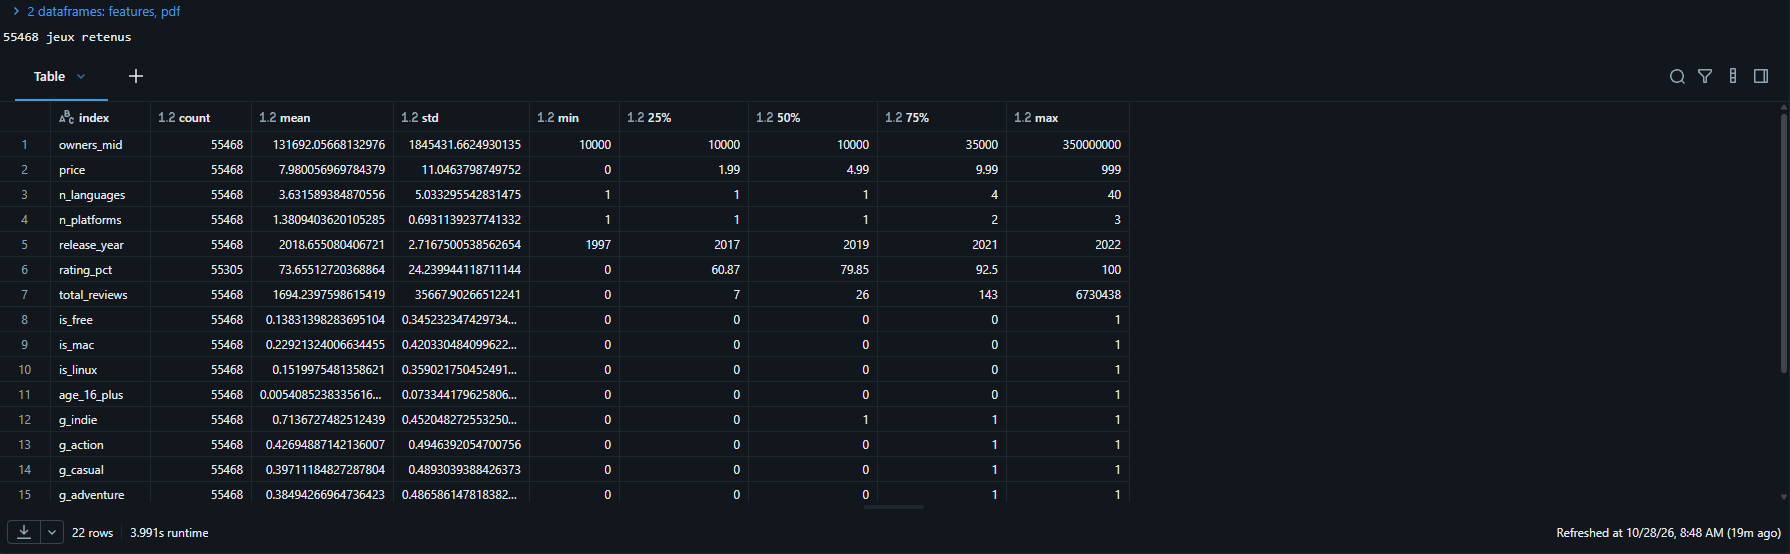

### 5.2 Régression linéaire multiple

On explique `log10(propriétaires)` par plusieurs variables **en même
temps**. Un coefficient `c` signifie que la variable multiplie le nombre
de propriétaires par `10^c`, les autres variables restant identiques
(colonne `facteur`). Un facteur de 2 = deux fois plus de propriétaires ;
1 = aucun effet ; 0,5 = deux fois moins.

Attention : on mesure des associations, pas des causes.

In [0]:
formula = (
    "log_owners ~ is_free + log_price + n_languages + n_platforms"
    " + age_16_plus + year_c"
    " + g_indie + g_action + g_casual + g_adventure"
    " + g_strategy + g_simulation + g_rpg"
)
model = smf.ols(formula, data=pdf).fit()
print(f"R² = {model.rsquared:.2f}")

coefs = pd.DataFrame({
    "variable": model.params.index,
    "coef": model.params.values.round(3),
    "facteur": (10 ** model.params.values).round(2),
    "p_value": model.pvalues.values.round(4),
}).query("variable != 'Intercept'")
display(coefs)

R² = 0.26


variable,coef,facteur,p_value
is_free,0.422,2.64,0.0
log_price,0.268,1.85,0.0
n_languages,0.023,1.05,0.0
n_platforms,0.049,1.12,0.0
age_16_plus,0.309,2.04,0.0
year_c,-0.071,0.85,0.0
g_indie,-0.068,0.86,0.0
g_action,0.057,1.14,0.0
g_casual,-0.064,0.86,0.0
g_adventure,0.011,1.03,0.0101


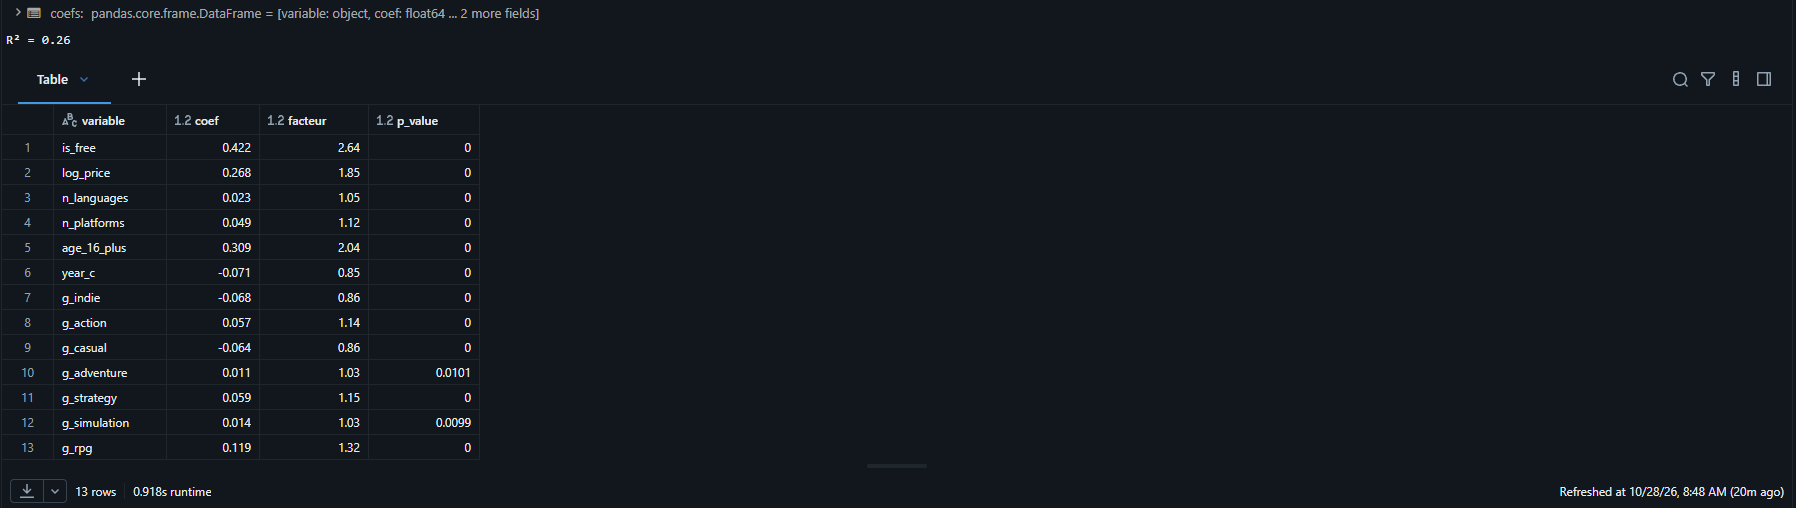

In [0]:
fig = px.bar(
    coefs.sort_values("facteur"),
    x="facteur",
    y="variable",
    orientation="h",
    title="Effet sur le nombre de propriétaires (1 = aucun effet)",
)
fig.add_vline(x=1, line_dash="dash")
fig.show()

<!doctype html>

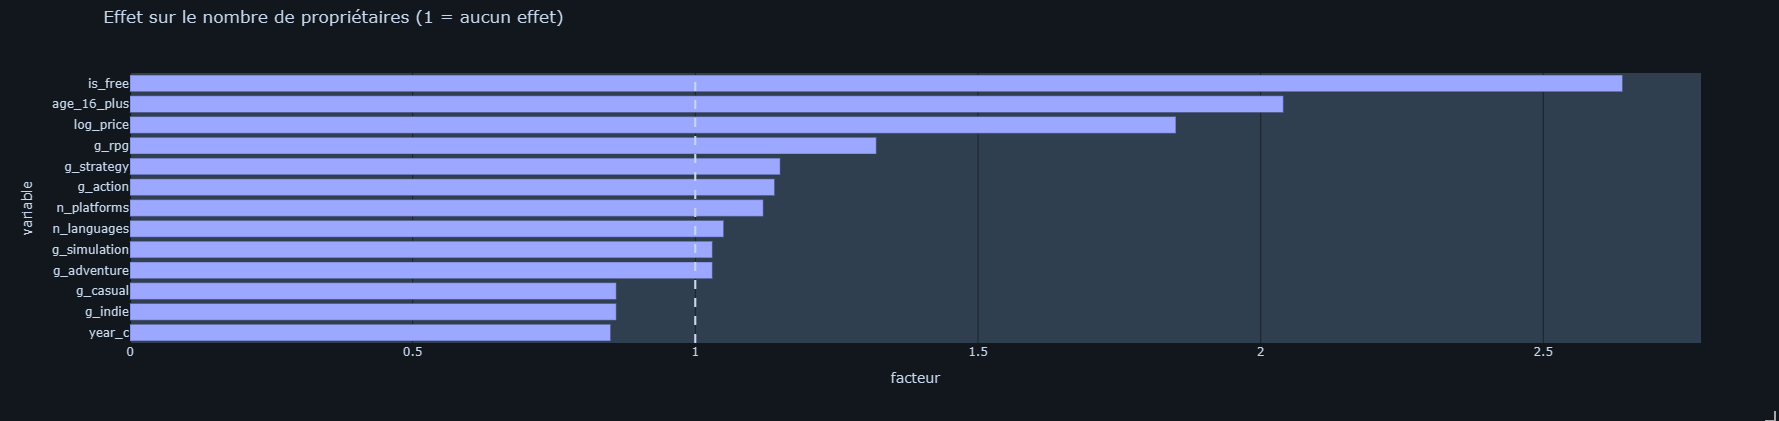

## 6. Conclusions et recommandations pour Ubisoft


**Constats**
- **Marché saturé et dominé par l'indé.** Environ 55 700 jeux, entre
  7 000 et 9 000 sorties par an depuis 2018. Ubisoft : 135 jeux, 7ème.
- **Pas de choc Covid sur les sorties.** 6 949 jeux en 2019, 8 287 en
  2020 (+19 %), 8 805 en 2021 (+6 %). 2022 est incomplète.
- **Petits prix.** 14 % de jeux gratuits, médiane des jeux payants à 5,99$, 78% des jeux sont à moins de 10$ (gratuits inclus), 5,5 % au-dessus de 20 $.
  4,5 % des jeux sont en promotion à la date de collecte.
- **Langues et âge.** L'anglais couvre 99 % des jeux, puis allemand
  (25 %), français (24 %), russe (23 %). 1,2 % des jeux sont déconseillés
  aux moins de 16 ans.
- **Genres.** Indie, Casual et Simulation ont les meilleurs ratios d'avis
  positifs, les jeux massivement multijoueurs les plus faibles. Le RPG a
  le revenu estimé médian par jeu le plus élevé.
- **Plateformes.** Environ 74 % des jeux ne sont que sur Windows ; Mac
  23 %, Linux 15 %. Indie et Strategy sont les genres les plus portés.
- **Popularité.** Gratuité, nombre de plateformes et de langues et genre
  RPG sont associés à plus de propriétaires (voir tableau de la
  régression).

**Recommandations**
- Viser une forte composante RPG ou stratégie plutôt que Casual ou Indie.
- Localiser largement et viser plusieurs plateformes.
- Arbitrer entre gratuité (audience) et prix premium (positionnement).

**Limites**
- Les propriétaires sont des tranches : le revenu est un ordre de
  grandeur.
- Prix et remises sont un instantané à la date de collecte.
- La régression montre des associations, pas des causes.